In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Exercise 6.4


Here we consider simulating the following continuous-time *logistic growth* model for $0 \le t < 50$ in Python, with $x(0) = 0.1$, $r = 0.2$, $K = 1$ and $\Delta t = 0.01$:

$$\frac{dx}{dt} = rx \left(1 - \frac{x}{K}\right) \tag{6.27}$$

> **Exercise 6.4** Vary $\Delta t$ to have larger values in the previous example and see how the simulation result is affected by such changes.
>
>

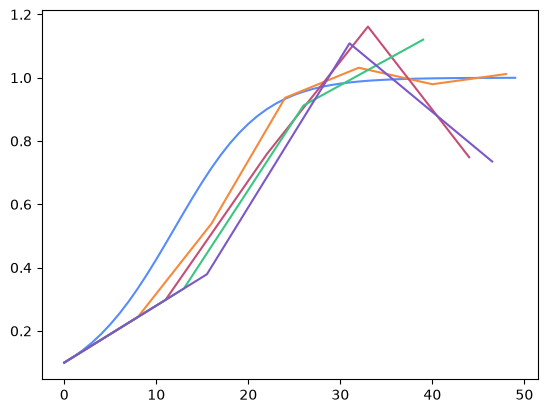

In [2]:
x_0 = 0.1
r = 0.2
K = 1
t_final = 50

for delta_t in [1.0, 8.0, 11.0, 13.0, 15.5]:
    t = np.arange(0, t_final, delta_t)
    x = np.zeros_like(t)
    x[0] = x_0

    for i in range(1, len(t)):
        x[i] = x[i-1] + r * x[i-1] * (1 - x[i-1] / K) * delta_t

    plt.plot(t, x, label=f'Δt={delta_t}')

# Exercise 6.5
Simulate the following continuous-time *Lotka–Volterra* (*predator–prey*) model for $0 \le t < 50$ in Python, with $x(0) = y(0) = 0.1$, $a = b = c = d = 1$ and $\Delta t = 0.01$. Visualize the simulation results over time and also in a phase space.
$$\frac{dx}{dt} = ax - bxy \tag{6.29}$$
$$\frac{dy}{dt} = -cy + dxy \tag{6.30}$$
Then try to reduce the value of $\Delta t$ to even smaller values and see how the simulation results are affected by such changes. Discuss what the overall results imply about the Euler forward method.

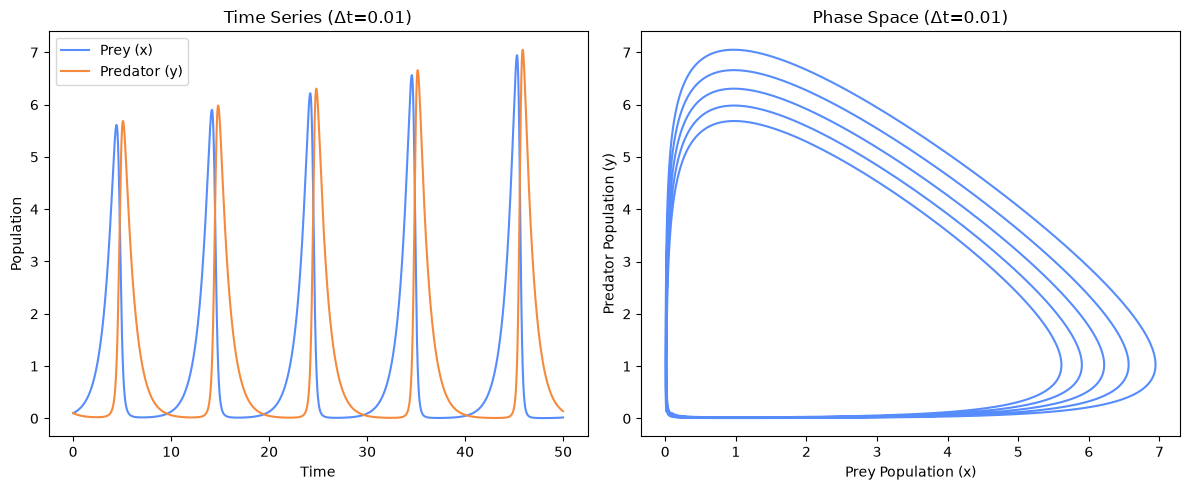

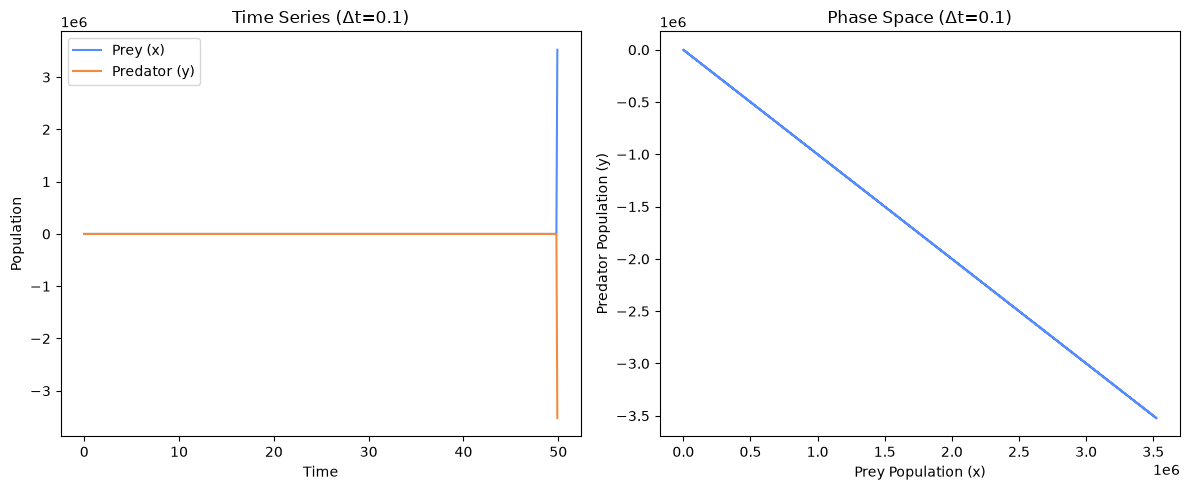

/var/folders/br/xflg5m_916s1bn1pdq6h9p3w0000gn/T/ipykernel_57477/2186953660.py:13: RuntimeWarning: overflow encountered in scalar multiply
  x[i] = x[i-1] + (a * x[i-1] - b * x[i-1] * y[i-1]) * delta_t
/var/folders/br/xflg5m_916s1bn1pdq6h9p3w0000gn/T/ipykernel_57477/2186953660.py:14: RuntimeWarning: overflow encountered in scalar multiply
  y[i] = y[i-1] + (-c * y[i-1] + d * x[i-1] * y[i-1]) * delta_t
/var/folders/br/xflg5m_916s1bn1pdq6h9p3w0000gn/T/ipykernel_57477/2186953660.py:14: RuntimeWarning: invalid value encountered in scalar add
  y[i] = y[i-1] + (-c * y[i-1] + d * x[i-1] * y[i-1]) * delta_t


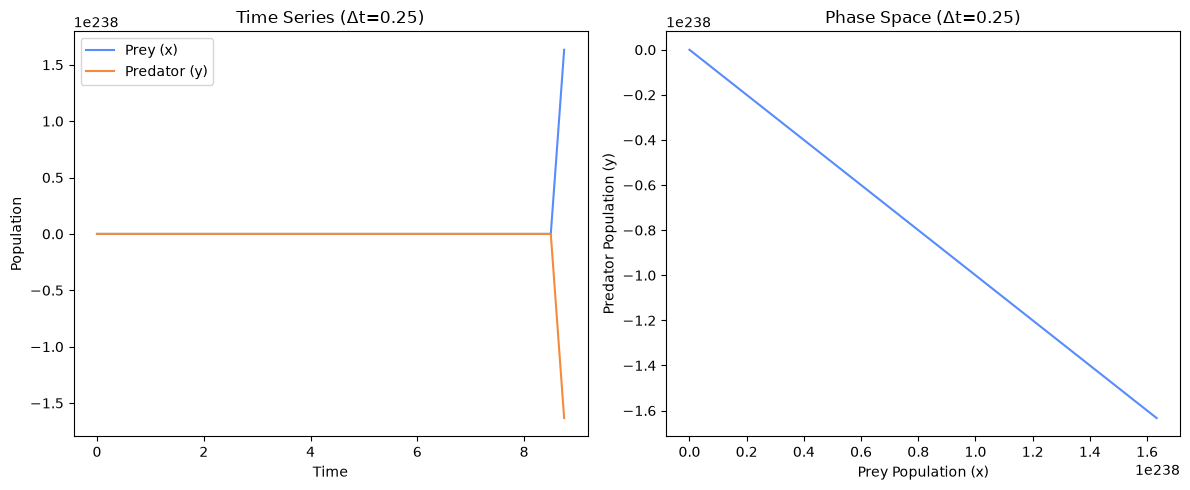

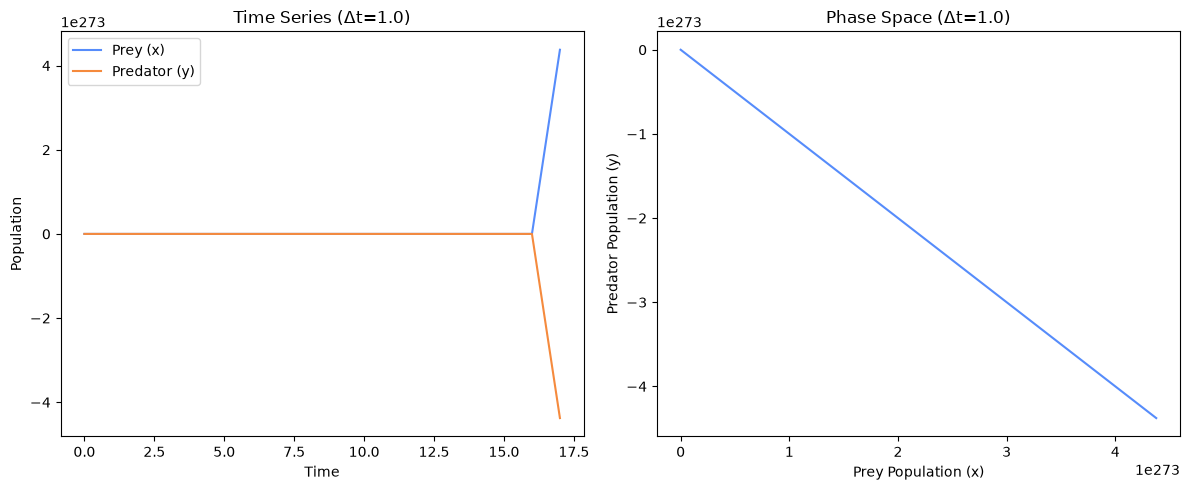

In [3]:
x_0 = y_0 = 0.1
a = b = c = d = 1
t_final = 50

for delta_t in [0.01, 0.1, 0.25, 1.0]:
    t = np.arange(0, t_final, delta_t)
    x = np.zeros_like(t)
    y = np.zeros_like(t)
    x[0] = x_0
    y[0] = y_0

    for i in range(1, len(t)):
        x[i] = x[i-1] + (a * x[i-1] - b * x[i-1] * y[i-1]) * delta_t
        y[i] = y[i-1] + (-c * y[i-1] + d * x[i-1] * y[i-1]) * delta_t

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(t, x, label='Prey (x)')
    plt.plot(t, y, label='Predator (y)')
    plt.title(f'Time Series (Δt={delta_t})')
    plt.xlabel('Time')
    plt.ylabel('Population')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(x, y)
    plt.title(f'Phase Space (Δt={delta_t})')
    plt.xlabel('Prey Population (x)')
    plt.ylabel('Predator Population (y)')

    plt.tight_layout()
    plt.show()

# Exercise 7.4 Draw a phase space of the following differential equation (motion of a simple pendulum) in Python:

$$\frac{d^2\theta}{dt^2} = -\frac{g}{L} \sin \theta$$

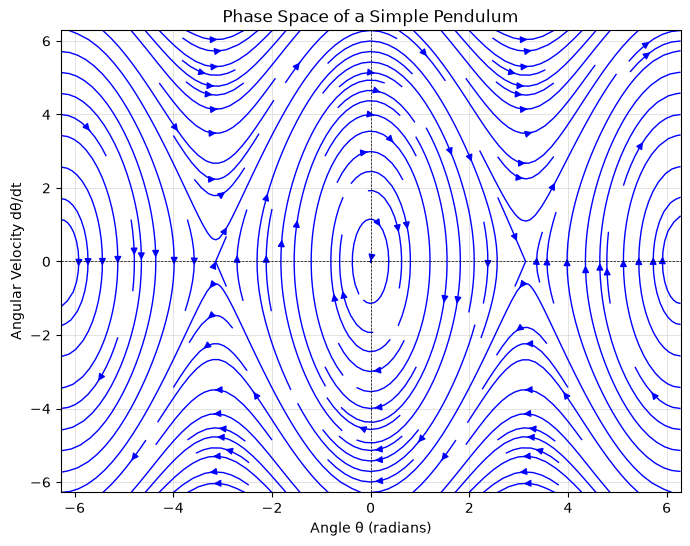

In [8]:
x = np.linspace(-2 * np.pi, 2 * np.pi, 100)
y = np.linspace(-2 * np.pi, 2 * np.pi, 100)
X, Y = np.meshgrid(x, y)
g = 9.81  # acceleration due to gravity
L = 1.0   # length of the pendulum
U = Y
V = - (g / L) * np.sin(X)

plt.figure(figsize=(8, 6))
plt.streamplot(X, Y, U, V, density=1.5, color='blue', linewidth=1)
plt.title('Phase Space of a Simple Pendulum')
plt.xlabel('Angle θ (radians)')
plt.ylabel('Angular Velocity dθ/dt')
plt.xlim([-2 * np.pi, 2 * np.pi])
plt.ylim([-2 * np.pi, 2 * np.pi])
plt.axhline(0, color='black', lw=0.5, ls='--')
plt.axvline(0, color='black', lw=0.5, ls='--')
plt.grid()
plt.show()